# 13 — Série temporal, efeito da pandemia e a queda de 2023

**Análises do plano:** A6 (efeito da pandemia, série mensal e casos esperados x observados) e a pergunta da
reunião "2023: queda de notificações".

**Definições**

- Cidade = município de residência; contagem por **mês e ano de diagnóstico**.
- Casos esperados em 2020-2024 = modelo de Poisson ajustado só em 2014-2019, com tendência linear, efeito do mês
  (sazonalidade) e a população como *offset*. A diferença observado − esperado estima os casos que "faltaram"
  (subdiagnóstico) ou que "sobraram" (busca acumulada).
- Bahia e Brasil vêm da tabela agregada do notebook 09 (casos novos por residência).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path('..', 'src').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import tb_utils as tb

tb.estilo()
df = tb.carrega_base()
ii = tb.residentes_ii(df)
pop = tb.carrega_populacao()
cores = tb.CORES_CIDADE
cods = {'Ilhéus': tb.COD_ILHEUS, 'Itabuna': tb.COD_ITABUNA}

## 1. Série mensal de casos novos

A linha fina é o mês; a linha grossa é a média móvel de 12 meses, que tira a sazonalidade e mostra a tendência.
A faixa cinza marca 2020-2021.

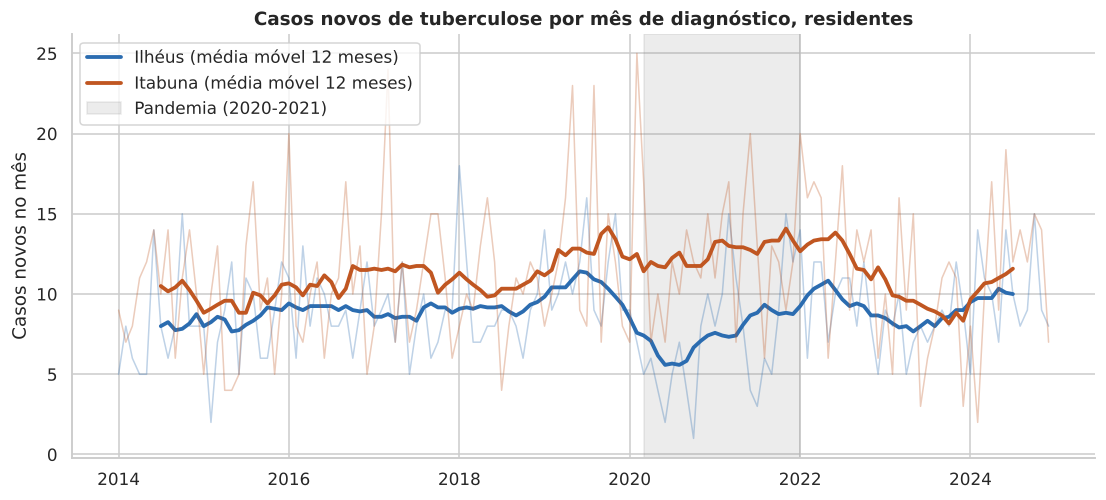

In [2]:
novos = ii[ii['caso_novo']].copy()
novos['mes'] = novos['dt_diag'].dt.to_period('M')
meses = pd.period_range('2014-01', '2024-12', freq='M')
serie = (novos.groupby(['cidade', 'mes']).size().unstack(0)
         .reindex(meses, fill_value=0).fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(12, 5))
x = serie.index.to_timestamp()
for c in serie.columns:
    ax.plot(x, serie[c], color=cores[c], alpha=0.3, lw=1)
    ax.plot(x, serie[c].rolling(12, center=True).mean(), color=cores[c], lw=2.5, label=f'{c} (média móvel 12 meses)')
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-31'), color='grey', alpha=0.15, label='Pandemia (2020-2021)')
ax.set_title('Casos novos de tuberculose por mês de diagnóstico, residentes')
ax.set_ylabel('Casos novos no mês')
ax.legend(loc='upper left')
tb.salva_fig(fig, '13_serie_mensal')
plt.show()

## 2. Casos esperados x observados (Poisson treinado em 2014-2019)

In [3]:
def esperado_vs_observado(serie_cidade, cod):
    d = serie_cidade.rename('casos').to_frame()
    d['ano'] = d.index.year
    d['mes_n'] = d.index.month
    d['t'] = np.arange(len(d))
    d['pop'] = [tb.pop_cidade_ano(pop, cod, a) for a in d['ano']]
    treino = d[d['ano'] <= 2019]
    mod = smf.glm('casos ~ t + C(mes_n)', data=treino, family=sm.families.Poisson(),
                  offset=np.log(treino['pop'])).fit()
    # Intervalo por simulação: incerteza dos parâmetros + variação de Poisson
    rng = np.random.default_rng(42)
    from patsy import dmatrix
    Xall = dmatrix('t + C(mes_n)', d, return_type='dataframe')[mod.params.index]
    betas = rng.multivariate_normal(mod.params, mod.cov_params(), size=2000)
    mu = np.exp(Xall.values @ betas.T + np.log(d['pop'].values)[:, None])
    d['esperado'] = mu.mean(axis=1)
    sim = rng.poisson(mu)
    anual = d.groupby('ano').agg(observado=('casos', 'sum'), esperado=('esperado', 'sum'))
    sim_ano = pd.DataFrame(sim, index=d['ano']).groupby(level=0).sum()
    anual['esperado_inf'] = sim_ano.quantile(0.025, axis=1)
    anual['esperado_sup'] = sim_ano.quantile(0.975, axis=1)
    anual['diferença'] = anual['observado'] - anual['esperado']
    anual['diferença %'] = 100 * anual['diferença'] / anual['esperado']
    anual['fora do intervalo'] = (anual['observado'] < anual['esperado_inf']) | (anual['observado'] > anual['esperado_sup'])
    return d, anual, mod

resultados = {}
for c, cod in cods.items():
    d, anual, mod = esperado_vs_observado(serie[c], cod)
    resultados[c] = (d, anual)
    print(f'\n{c}: tendência mensal do modelo = {100*(np.exp(mod.params["t"]*12)-1):+.1f}% ao ano em 2014-2019 (p = {tb.fmt_p(mod.pvalues["t"])})')

tabela_esp = pd.concat({c: r[1] for c, r in resultados.items()}, names=['cidade'])
tabela_esp.round(1)


Ilhéus: tendência mensal do modelo = +6.6% ao ano em 2014-2019 (p = 0,006)



Itabuna: tendência mensal do modelo = +5.1% ao ano em 2014-2019 (p = 0,018)


observado  esperado  esperado_inf  esperado_sup  diferença  \
cidade  ano                                                                
Ilhéus  2014         96      93.7          70.0         117.0        2.3   
        2015         97      99.5          77.0         122.0       -2.5   
        2016        111     105.6          84.0         128.0        5.4   
        2017        100     112.2          91.0         136.0      -12.2   
        2018        111     119.3          96.0         144.0       -8.3   
        2019        136     126.9         101.0         156.0        9.1   
        2020         68     135.1         106.0         168.0      -67.1   
        2021        106     143.8         109.0         184.0      -37.8   
        2022        116     153.2         110.0         202.0      -37.2   
        2023        100     163.3         114.0         224.0      -63.3   
        2024        120     174.2         118.0         248.0      -54.2   
Itabuna 2014        126     117.3          93.0         144.0        8.7   
        2015        106     122.3          98.0         149.0      -16.3   
        2016        129     127.5         104.0         153.0        1.5   
        2017        141     133.0         109.0         159.0        8.0   
        2018        124     138.8         114.0         167.0      -14.8   
        2019        151     145.0         115.0         176.0        6.0   
        2020        147     151.5         120.0         185.0       -4.5   
        2021        150     158.3         121.0         200.0       -8.3   
        2022        160     165.5         123.0         212.0       -5.5   
        2023        109     173.2         123.0         231.0      -64.2   
        2024        139     181.2         125.0         250.0      -42.2   

              diferença %  fora do intervalo  
cidade  ano                                   
Ilhéus  2014          2.5              False  
        2015         -2.5              False  
        2016          5.1              False  
        2017        -10.9              False  
        2018         -7.0              False  
        2019          7.2              False  
        2020        -49.7               True  
        2021        -26.3               True  
        2022        -24.3              False  
        2023        -38.8               True  
        2024        -31.1              False  
Itabuna 2014          7.4              False  
        2015        -13.3              False  
        2016          1.2              False  
        2017          6.0              False  
        2018        -10.7              False  
        2019          4.1              False  
        2020         -3.0              False  
        2021         -5.2              False  
        2022         -3.3              False  
        2023        -37.1               True  
        2024        -23.3              False

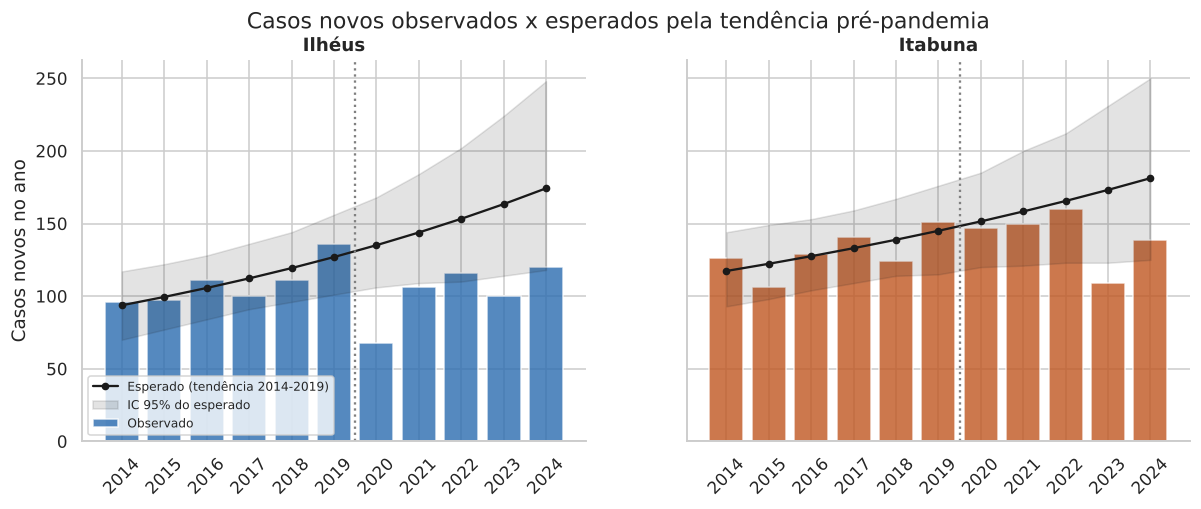

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (c, (d, anual)) in zip(axes, resultados.items()):
    ax.bar(anual.index, anual['observado'], color=cores[c], alpha=0.8, label='Observado')
    ax.plot(anual.index, anual['esperado'], 'k-o', ms=4, label='Esperado (tendência 2014-2019)')
    ax.fill_between(anual.index, anual['esperado_inf'], anual['esperado_sup'], color='k', alpha=0.12, label='IC 95% do esperado')
    ax.axvline(2019.5, color='grey', ls=':')
    ax.set_title(c)
    ax.set_xticks(list(tb.ANOS))
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Casos novos no ano')
axes[0].legend(loc='lower left', fontsize=8)
fig.suptitle('Casos novos observados x esperados pela tendência pré-pandemia')
tb.salva_fig(fig, '13_esperado_observado')
plt.show()

In [5]:
pand = tabela_esp.reset_index()
for c in cods:
    p = pand[(pand['cidade'] == c) & pand['ano'].between(2020, 2021)]
    falt = p['diferença'].sum()
    print(f'{c}: 2020-2021 observou {int(p.observado.sum())} casos novos para {p.esperado.sum():.0f} esperados '
          f'({falt:+.0f}; {100*falt/p.esperado.sum():+.1f}%).')

Ilhéus: 2020-2021 observou 174 casos novos para 279 esperados (-105; -37.6%).
Itabuna: 2020-2021 observou 297 casos novos para 310 esperados (-13; -4.1%).


## 3. Abandono e óbito durante a pandemia

Coorte de casos novos por período de diagnóstico, com IC de Wilson.

In [6]:
coorte = ii[ii['coorte_casos_novos'] & ii['desfecho'].ne('Sem encerramento')].copy()
coorte['periodo'] = pd.cut(coorte['ano_diag'], [2013, 2019, 2021, 2024], labels=['2014-2019', '2020-2021', '2022-2024'])
linhas = []
for (c, per), g in coorte.groupby(['cidade', 'periodo'], observed=True):
    for ind, col in [('Cura', 'cura'), ('Abandono', 'abandono'), ('Óbito por TB', 'obito_tb')]:
        k, n = int(g[col].sum()), len(g)
        p = 100 * k / n
        lo, hi = tb.ic_proporcao(k, n)
        linhas.append({'cidade': c, 'período': per, 'indicador': ind, 'n': n, '%': p, 'IC inf': lo, 'IC sup': hi})
desf_periodo = pd.DataFrame(linhas)
desf_periodo.pivot_table(index=['indicador', 'período'], columns='cidade', values='%', observed=True).round(1)

cidade                  Ilhéus  Itabuna
indicador    período                   
Abandono     2014-2019    10.1     11.1
             2020-2021    10.6     16.6
             2022-2024    15.4     14.7
Cura         2014-2019    80.4     78.1
             2020-2021    78.2     70.2
             2022-2024    75.8     70.8
Óbito por TB 2014-2019     3.1      4.5
             2020-2021     1.8      7.8
             2022-2024     0.7      6.7

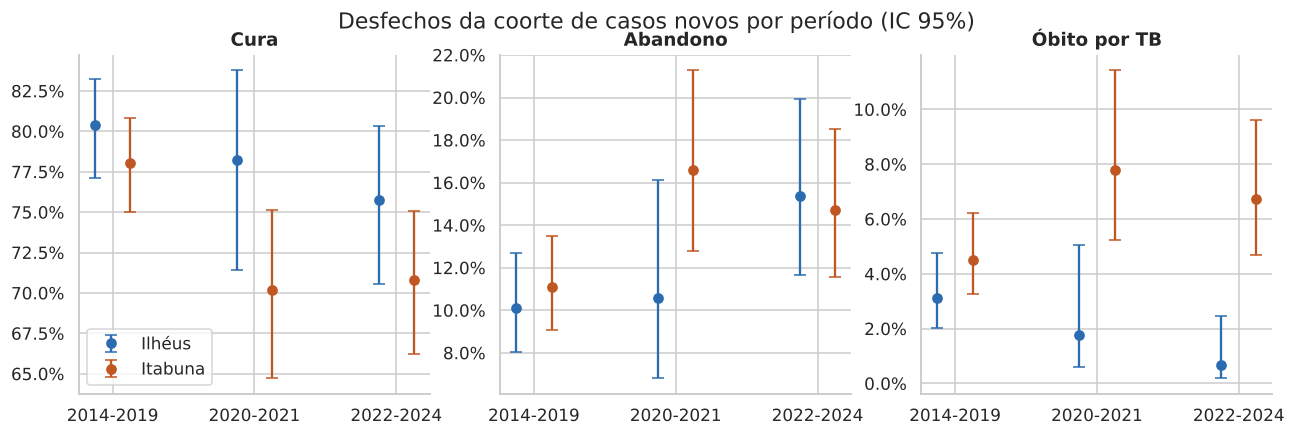

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, ind in zip(axes, ['Cura', 'Abandono', 'Óbito por TB']):
    sub = desf_periodo[desf_periodo['indicador'] == ind]
    for i, c in enumerate(cods):
        s = sub[sub['cidade'] == c]
        xs = np.arange(len(s)) + (i - 0.5) * 0.25
        ax.errorbar(xs, s['%'], yerr=[s['%'] - s['IC inf'], s['IC sup'] - s['%']], fmt='o', color=cores[c],
                    capsize=4, label=c)
    ax.set_xticks(range(3))
    ax.set_xticklabels(['2014-2019', '2020-2021', '2022-2024'])
    ax.set_title(ind)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].legend()
fig.suptitle('Desfechos da coorte de casos novos por período (IC 95%)')
tb.salva_fig(fig, '13_desfechos_periodo')
plt.show()

In [8]:
# Fisher: abandono 2020-2021 x 2014-2019 em cada cidade
for c in cods:
    g = coorte[coorte['cidade'] == c]
    a = g[g['periodo'] == '2020-2021']; b = g[g['periodo'] == '2014-2019']
    for ind, col in [('abandono', 'abandono'), ('óbito por TB', 'obito_tb')]:
        orr, lo, hi, p = tb.fisher_2x2(int(a[col].sum()), len(a) - int(a[col].sum()), int(b[col].sum()), len(b) - int(b[col].sum()))
        print(f'{c}, {ind} 2020-2021 x 2014-2019: OR {orr:.2f} ({lo:.2f}–{hi:.2f}), p = {tb.fmt_p(p)}')

Ilhéus, abandono 2020-2021 x 2014-2019: OR 1.05 (0.61–1.83), p = 0,887
Ilhéus, óbito por TB 2020-2021 x 2014-2019: OR 0.56 (0.16–1.90), p = 0,443
Itabuna, abandono 2020-2021 x 2014-2019: OR 1.60 (1.09–2.33), p = 0,018
Itabuna, óbito por TB 2020-2021 x 2014-2019: OR 1.79 (1.04–3.08), p = 0,048


## 4. A queda de 2023

Pergunta da reunião: por que as notificações caem em 2023? Verificamos, em ordem:

1. se a queda é de casos novos ou de retratamentos;
2. se ela também aparece na Bahia, no Brasil e nas outras cidades de comparação;
3. em que meses e em qual grupo de pacientes (privados de liberdade x população geral) ela acontece;
4. se há sinal de atraso de digitação ou de registro incompleto no arquivo de 2023.

In [9]:
tipo = ii.assign(grupo=np.where(ii['caso_novo'], 'Caso novo', np.where(ii['retratamento'], 'Retratamento', 'Outros/ignorado')))
pd.crosstab([tipo['cidade'], tipo['grupo']], tipo['ano_diag'])

ano_diag                 2014  2015  2016  2017  2018  2019  2020  2021  2022  \
cidade  grupo                                                                   
Ilhéus  Caso novo          96    97   111   100   111   136    68   106   116   
        Outros/ignorado     6     4    11     6     3     6     7    13    10   
        Retratamento       12    31    22    19    19    21    27    23    27   
Itabuna Caso novo         126   106   129   141   124   151   147   150   160   
        Outros/ignorado     1     1     4     7     2     0     2     8     3   
        Retratamento       14    12    18    25    17    19    21    26    31   

ano_diag                 2023  2024  
cidade  grupo                        
Ilhéus  Caso novo         100   120  
        Outros/ignorado     7    12  
        Retratamento       19    23  
Itabuna Caso novo         109   139  
        Outros/ignorado     5     1  
        Retratamento       31    32

In [10]:
agreg = pd.read_csv(tb.PROCESSED / 'tb_brasil_agregado.csv.gz', dtype={'SG_UF': str, 'ID_MN_RESI': str, 'TRATAMENTO': str})
agreg = agreg[agreg['TRATAMENTO'].eq('1') & agreg['ano_diag'].between(2014, 2024)]
var = {}
var['Ilhéus'] = serie['Ilhéus'].groupby(serie.index.year).sum()
var['Itabuna'] = serie['Itabuna'].groupby(serie.index.year).sum()
var['Bahia'] = agreg[agreg['SG_UF'].eq('29')].groupby('ano_diag')['casos'].sum()
var['Bahia sem Ilhéus e Itabuna'] = agreg[agreg['SG_UF'].eq('29') & ~agreg['ID_MN_RESI'].isin([tb.COD_ILHEUS, tb.COD_ITABUNA])].groupby('ano_diag')['casos'].sum()
var['Brasil'] = agreg.groupby('ano_diag')['casos'].sum()
for cod, nome in tb.CIDADES.items():
    if nome not in ('Ilhéus', 'Itabuna'):
        var[nome] = agreg[agreg['ID_MN_RESI'].eq(cod)].groupby('ano_diag')['casos'].sum()
var = pd.DataFrame(var).T
variacao = pd.DataFrame({
    'casos 2022': var[2022], 'casos 2023': var[2023], 'casos 2024': var[2024],
    'variação 2022→2023 (%)': 100 * (var[2023] / var[2022] - 1),
    'variação 2023→2024 (%)': 100 * (var[2024] / var[2023] - 1),
})
variacao.round(1)

,casos 2022,casos 2023,casos 2024,variação 2022→2023 (%),variação 2023→2024 (%)
Ilhéus,116,100,120,-13.8,20.0
Itabuna,160,109,139,-31.9,27.5
Bahia,4278,4277,4390,-0.0,2.6
Bahia sem Ilhéus e Itabuna,4002,4068,4131,1.6,1.5
Brasil,79765,83380,84632,4.5,1.5
Vitória da Conquista,51,54,73,5.9,35.2
Feira de Santana,154,167,127,8.4,-24.0
Salvador,1390,1447,1433,4.1,-1.0
Recife,1723,1669,1542,-3.1,-7.6
Aracaju,278,286,250,2.9,-12.6


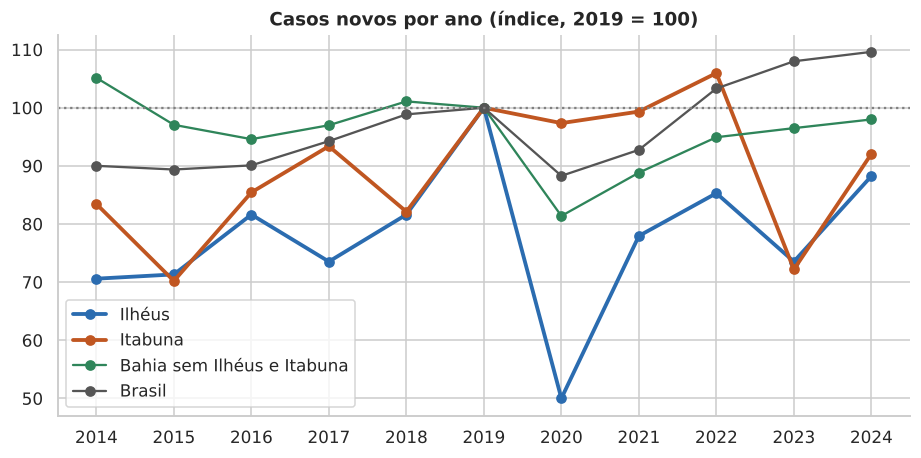

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
idx = var.div(var[2019], axis=0) * 100
for nome in ['Ilhéus', 'Itabuna', 'Bahia sem Ilhéus e Itabuna', 'Brasil']:
    ax.plot(idx.columns, idx.loc[nome], marker='o', lw=2.5 if nome in cores else 1.5,
            color={**cores, 'Brasil': '#555555', 'Bahia sem Ilhéus e Itabuna': '#2f855a'}[nome], label=nome)
ax.axhline(100, color='grey', ls=':')
ax.set_title('Casos novos por ano (índice, 2019 = 100)')
ax.set_xticks(list(tb.ANOS))
ax.legend()
tb.salva_fig(fig, '13_indice_2019')
plt.show()

### Em que meses e em qual grupo a queda aparece

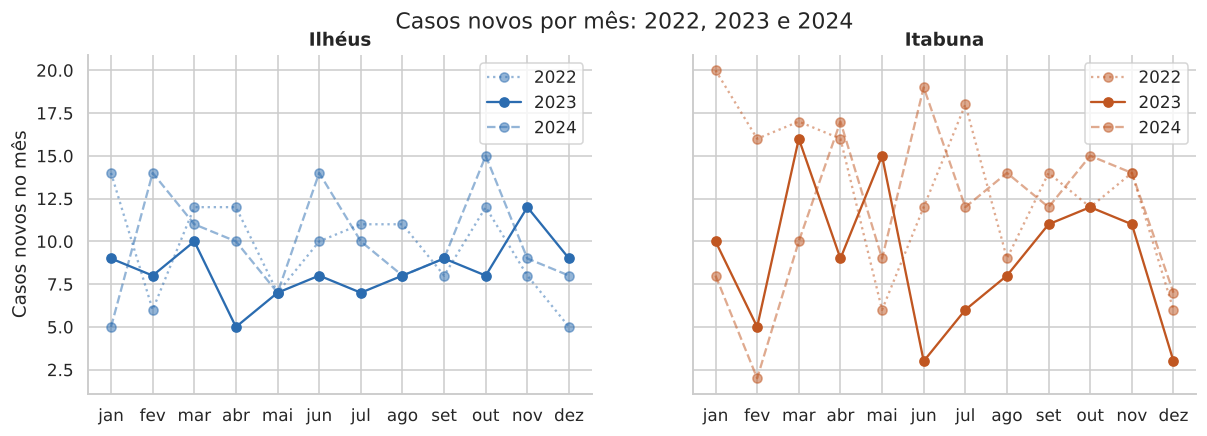

In [12]:
mes22_24 = serie.loc['2022-01':'2024-12'].copy()
mes22_24.index = mes22_24.index.astype(str)
comp_mes = pd.DataFrame({c: [serie.loc[f'{a}-01':f'{a}-12', c].values for a in (2022, 2023, 2024)] for c in cods})
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
nomes_mes = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
for ax, c in zip(axes, cods):
    for a, est in zip((2022, 2023, 2024), [':', '-', '--']):
        ax.plot(nomes_mes, serie.loc[f'{a}-01':f'{a}-12', c].values, est, marker='o', color=cores[c],
                alpha=1 if a == 2023 else 0.5, label=str(a))
    ax.set_title(c)
    ax.legend()
axes[0].set_ylabel('Casos novos no mês')
fig.suptitle('Casos novos por mês: 2022, 2023 e 2024')
tb.salva_fig(fig, '13_meses_2022_2024')
plt.show()

In [13]:
novos['prisional'] = novos['privado_liberdade'].map({1.0: 'Privado de liberdade', 0.0: 'População geral'}).fillna('Ignorado')
pd.crosstab([novos['cidade'], novos['prisional']], novos['ano_diag']).loc[:, 2019:]

ano_diag                      2019  2020  2021  2022  2023  2024
cidade  prisional                                               
Ilhéus  Ignorado                 4     1     3     5     2     4
        População geral        127    65   100   108    97   115
        Privado de liberdade     5     2     3     3     1     1
Itabuna Ignorado                 5     1     1     2     1     2
        População geral        106   113   125   145    91   119
        Privado de liberdade    40    33    24    13    17    18

In [14]:
# Unidade notificadora e município de notificação dos casos novos (2022 x 2023)
sub = novos[novos['ano_diag'].isin([2022, 2023, 2024])]
pd.crosstab([sub['cidade'], sub['tipo_unidade'].fillna('Sem informação')], sub['ano_diag'])

ano_diag                          2022  2023  2024
cidade  tipo_unidade                              
Ilhéus  Centro de saúde / UBS       99    80    92
        Hospital especializado       0     0     1
        Hospital geral              16    20    26
        Outros / não informado       1     0     0
        Pronto atendimento (UPA)     0     0     1
Itabuna Centro de saúde / UBS      137    93   112
        Hospital especializado       1     2     2
        Hospital geral              22    14    24
        Pronto atendimento (UPA)     0     0     1

### Atraso de digitação e encerramento

Se o arquivo de 2023 tivesse sido extraído antes de todos os casos serem digitados, esperaríamos uma queda
concentrada nos últimos meses do ano e casos digitados com atraso maior. Medimos os dias entre a notificação e a
digitação e a proporção de casos sem encerramento.

In [15]:
ii['dias_digitacao'] = (ii['dt_digita'] - ii['dt_notific']).dt.days
dig = ii[ii['ano_diag'] >= 2018].groupby(['cidade', 'ano_diag']).agg(
    mediana_dias_digitacao=('dias_digitacao', 'median'),
    p90_dias_digitacao=('dias_digitacao', lambda s: s.quantile(0.9)),
    sem_encerramento_pct=('desfecho', lambda s: 100 * s.eq('Sem encerramento').mean()),
    transferencia_pct=('desfecho', lambda s: 100 * s.eq('Transferência').mean()),
)
dig.round(1).unstack(0)

mediana_dias_digitacao         p90_dias_digitacao          \
cidade                   Ilhéus Itabuna             Ilhéus Itabuna   
ano_diag                                                             
2018                       27.0    15.0               62.0    52.0   
2019                       41.0    13.5               92.0    34.0   
2020                       42.0    25.0               96.7    90.0   
2021                       31.0    15.0               75.8    71.4   
2022                       37.0     9.0               68.8    28.0   
2023                       47.5     8.0               88.0    62.2   
2024                       42.0    15.0               83.0    50.9   

         sem_encerramento_pct         transferencia_pct          
cidade                 Ilhéus Itabuna            Ilhéus Itabuna  
ano_diag                                                         
2018                      3.0     0.0               5.3     2.8  
2019                      4.3     1.2               3.7     0.6  
2020                      2.0     0.6               2.9     1.8  
2021                      2.8     0.5               2.8     2.7  
2022                      7.2     0.0               3.3     4.6  
2023                     12.7     0.0               2.4     4.1  
2024                     20.0     7.6               2.6     4.1

In [16]:
# Mesma análise na Bahia toda (excluindo Ilhéus e Itabuna)
ba = df[df['uf_res'].eq('29') & ~df['mun_res'].isin([tb.COD_ILHEUS, tb.COD_ITABUNA]) & df['ano_diag'].ge(2018)].copy()
ba['dias_digitacao'] = (ba['dt_digita'] - ba['dt_notific']).dt.days
ba.groupby('ano_diag').agg(mediana_dias_digitacao=('dias_digitacao', 'median'),
                           sem_encerramento_pct=('desfecho', lambda s: 100 * s.eq('Sem encerramento').mean())).round(1).T

ano_diag,2018,2019,2020,2021,2022,2023,2024
mediana_dias_digitacao,9.0,10.0,10.0,8.0,8.0,8.0,7.0
sem_encerramento_pct,6.9,8.5,9.1,8.9,9.4,10.2,23.4


In [17]:
tabela_esp.to_csv(tb.PROCESSED / 'esperado_observado_pandemia.csv')
variacao.to_csv(tb.PROCESSED / 'variacao_2022_2024.csv')

## Conclusões

1. **Pandemia em Ilhéus.** Em 2020-2021 Ilhéus registrou 174 casos novos para 279 esperados pela tendência de
   2014-2019 (cerca de 105 a menos, −38%). Em 2020 a queda foi de 50%, fora do intervalo esperado. Como a TB não
   desaparece, isso indica casos não diagnosticados naquele período, que continuaram transmitindo (ver notebook 11).
2. **Pandemia em Itabuna.** Itabuna manteve o número de diagnósticos (297 para 310 esperados, −4%), mas piorou o
   acompanhamento: abandono subiu de 11,1% para 16,6% (OR 1,60; p = 0,018) e óbito por TB de 4,5% para 7,8%
   (OR 1,79; p = 0,048). Em Ilhéus abandono e óbito não mudaram.
3. **Depois da pandemia.** Em 2022-2024 o abandono de Ilhéus subiu para 15,4%, e as duas cidades ficaram abaixo do
   esperado. A projeção da tendência pré-pandemia (+5% a +7% ao ano) acumula incerteza com o tempo, então os
   números de 2022-2024 devem ser lidos como tendência, não como estimativa exata.
4. **A queda de 2023 é local, sobretudo de Itabuna.** Casos novos caíram 32% em Itabuna (160 → 109) e 14% em
   Ilhéus (116 → 100), enquanto a Bahia sem as duas cidades subiu 1,6% e o Brasil 4,5%. Nenhuma das outras oito
   cidades caiu tanto. Os retratamentos não caíram, e em 2024 as duas cidades voltaram a crescer (+28% e +20%).
5. **Onde a queda acontece em Itabuna.** Ela se espalha pelos quatro trimestres de 2023, está na população geral
   (145 → 91; os casos no sistema prisional ficaram estáveis) e nas UBS (137 → 93). O atraso de digitação em
   Itabuna foi o menor da série (mediana de 8 dias), então não é um arquivo incompleto. O padrão aponta para
   menos diagnóstico na atenção básica em 2023 (por exemplo, falta de insumo ou de equipe, ou mudança de fluxo),
   o que é uma pergunta para a vigilância municipal.
6. **Encerramento pendente.** Casos sem encerramento crescem nos anos recentes (Ilhéus 20% em 2024), então os
   desfechos de 2023-2024 ainda podem mudar.